# Multivariable calculus 2: Partial derivatives and the gradient

*Learning path: multivariable calculus, part 2 of 7.* [Index](README.md) · Previous: [Functions of two variables](01-functions-of-two-variables.ipynb) · Next: [Optimization](03-optimization.ipynb)

You stand on a hillside in fog. You can't see the map, but you can feel the ground under your feet. Which way is
straight uphill, and how steep is it? If you walk north-east instead, how fast do you climb? This lesson answers
those questions with one object, the **gradient**, built from ordinary derivatives.

**Who this is for.** You know derivatives of one variable, including the chain rule
([foundations 7](../foundations/07-calculus.ipynb)), and level curves ([lesson 1](01-functions-of-two-variables.ipynb)).
The dot product of two vectors helps ([linear algebra 1](../linear-algebra/01-vectors-and-matrices.ipynb)); we
recall what we need.

**What you will be able to do afterwards:**

1. compute partial derivatives by hand and explain them as slopes of slices;
2. write the tangent plane of a surface and use it to approximate $f$ near a point;
3. compute a directional derivative and the gradient, and say why the gradient points straight uphill;
4. explain why the gradient is perpendicular to the level curves.

Plan about an hour. Galileo is used to check you: do each derivative by hand first, then run the cell.

## 1. Partial derivatives: slopes of slices

In lesson 1 we sliced the dome $f(x, y) = 9 - x^2 - y^2$ with planes $y = $ constant. On each slice $f$ is a
function of $x$ alone, and it has an ordinary derivative. That derivative is the **partial derivative** with
respect to $x$:

$$\frac{\partial f}{\partial x} = \text{the derivative of } f \text{ in } x \text{, treating } y \text{ as a constant.}$$

For the dome, by hand: $\partial f/\partial x = -2x$ and $\partial f/\partial y = -2y$. In Galileo `diff(f, x)`
treats every other letter as a constant:

In [1]:
f = 9 - x^2 - y^2
diff(f, x)
diff(f, y)

9-x^2-y^2

-2*x

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

-2*y

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

A messier one, $g(x, y) = x^2 y^3 + \sin(xy)$. By hand: in $\partial g/\partial x$ the factor $y^3$ is a constant,
and $\sin(xy)$ needs the chain rule with inner derivative $y$. So $\partial g/\partial x = 2xy^3 + y\cos(xy)$.
Predict $\partial g/\partial y$ yourself, then check:

In [2]:
g = x^2*y^3 + sin(x*y)
diff(g, x)
diff(g, y)

x^2*y^3+sin(x*y)

2*x*y^3+y*cos(x*y)

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

3*x^2*y^2+x*cos(x*y)

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

**Second derivatives.** Differentiate again: $g_{xx}$, $g_{yy}$, and the **mixed** ones $g_{xy}$ (first $x$, then
$y$) and $g_{yx}$. Compute both mixed ones:

In [3]:
diff(diff(g, x), y)
diff(diff(g, y), x)

6*x*y^2-x*y*sin(x*y)+cos(x*y)

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

6*x*y^2-x*y*sin(x*y)+cos(x*y)

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

They are equal. That is **Clairaut's theorem**: when the second partial derivatives are continuous, the order
doesn't matter. It will matter in lesson 6, where it becomes the test for a force field to have a potential energy.

**Try this.** For $h(x, y) = e^{x} \cos y$ compute $h_{xx} + h_{yy}$ by hand. Check with Galileo. (A function with
$h_{xx} + h_{yy} = 0$ is called harmonic; steady temperatures in a plate are harmonic.)

## 2. The tangent plane and linear approximation

For one variable, the tangent line $y = f(a) + f'(a)(x - a)$ is the best straight-line approximation of $f$ near
$a$. With two variables the graph is a surface, and the best flat approximation is the **tangent plane** through
$(a, b, f(a, b))$:

$$z = f(a, b) + f_x(a, b)\,(x - a) + f_y(a, b)\,(y - b).$$

Each slope is the slope of a slice, so the plane matches the surface in both directions. For the dome at
$(1, 2)$: $f = 4$, $f_x = -2$, $f_y = -4$, so $z = 4 - 2(x - 1) - 4(y - 2)$. Let us use it to estimate $f(1.1, 1.9)$:

In [4]:
L = 4 - 2*(x - 1) - 4*(y - 2)
subs(subs(L, x, 1.1), y, 1.9)
subs(subs(f, x, 1.1), y, 1.9)

14-2*x-4*y

4.2

> `subs`: Replaces the variable x by a value.

4.18

> `subs`: Replaces the variable x by a value.

The plane says $4.2$, the true value is $4.18$: the error is $0.02$, exactly the size of the squares of the steps
($0.1^2 + 0.1^2 = 0.02$), just as for one variable the error of the tangent line is of the order of the step squared.

**Try this.** Write the tangent plane of $g(x, y) = \sqrt{x^2 + y^2}$ at $(3, 4)$ by hand and use it to estimate
$\sqrt{3.02^2 + 3.97^2}$. Compare with `eval(sqrt(3.02^2 + 3.97^2))`.

## 3. Walking in any direction: the directional derivative

How fast does $f$ change if we walk from $(a, b)$ in the direction of a **unit** vector $u = [u_1, u_2]$? Walk a
distance $t$: we are at $(a + t u_1, b + t u_2)$, and by the tangent plane

$$f(a + tu_1, b + tu_2) \approx f(a, b) + t\,(f_x u_1 + f_y u_2).$$

So the rate of change is

$$D_u f = f_x u_1 + f_y u_2 = [f_x, f_y] \cdot u.$$

The vector of partial derivatives deserves a name: it is the **gradient**, $\nabla f = [f_x, f_y]$, and `grad`
computes it:

In [5]:
G = grad(9 - x^2 - y^2, [x y])
P = subs(subs(G, x, 1), y, 2)

[-2*x, -2*y]

> The gradient lists the partial derivatives [∂f/∂x, ∂f/∂y]. It points in the direction in which f increases fastest, its length is that fastest rate, and it is perpendicular to the level curves (or surfaces) of f.

[-2, -4]

> `subs`: Replaces the variable x by a value.

At $(1, 2)$ the gradient is $[-2, -4]$. Walking east, $u = [1, 0]$, gives $D_u f = -2$. Walking north-east,
$u = [1, 1]/\sqrt 2$:

In [6]:
dot(P, [1 1]/sqrt(2))

-3*sqrt(2)

> `dot`: Dot product of two vectors, and cross product of two vectors of length 3.

$-6/\sqrt 2 \approx -4.24$: downhill, and steeper than going east.

**Try this.** At the same point, find a direction $u$ in which $D_u f = 0$: you walk without going up or down.
(Hint: $\nabla f \cdot u = 0$.) Which level curve are you walking along?

## 4. Why the gradient points straight uphill

Which direction gives the **largest** $D_u f$? A dot product is $|\nabla f|\,|u| \cos\theta$ with $\theta$ the angle
between the two vectors, and $|u| = 1$. So

$$D_u f = |\nabla f| \cos\theta,$$

largest when $\theta = 0$: walking **along the gradient**. Three facts follow at once:

* the gradient points in the direction of steepest ascent;
* its length $|\nabla f|$ is that steepest slope;
* walking at right angles to it ($\cos\theta = 0$) you stay at the same height: the gradient is **perpendicular to
  the level curve** through the point.

See all three in one picture: the level curves of $x^2 + 3y^2$ with its gradient field drawn as arrows.

x^2+3*y^2

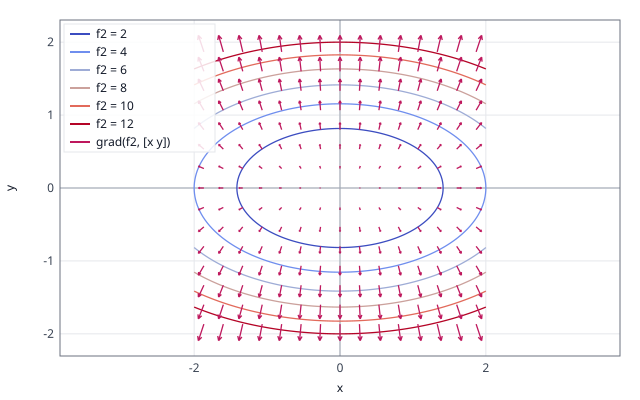

> `show`: Overlays plots: all 2D, or all 3D.

In [7]:
f2 = x^2 + 3*y^2
show(contour(f2, x, -2, 2, y, -2, 2), fieldplot(grad(f2, [x y]), x, -2, 2, y, -2, 2))

How to read the plot: `contour` draws level curves; `fieldplot([P Q], x, ..., y, ...)` draws an arrow for the
vector $[P, Q]$ at the middle of each cell, scaled so the longest arrow fills its cell; `show` overlays them. Every
arrow crosses the ellipses at a right angle and points outward, toward higher values. The arrows are longest where
the ellipses crowd together: steep places.

**Try this.** Draw the same picture for the saddle $x^2 - y^2$. Where are the arrows shortest? What happens exactly
at the origin?

## 5. Gradients in polar and spherical coordinates

Many problems are round: the temperature around a heater, the potential around a charge. The gradient then looks
different, because a step $d\theta$ in angle is a distance $r\,d\theta$, not $d\theta$. In polar coordinates

$$\nabla f = \left[\frac{\partial f}{\partial r},\ \frac{1}{r}\frac{\partial f}{\partial \theta}\right]$$

along the unit vectors $\hat r$ and $\hat\theta$. Galileo takes the coordinate system as a third argument:

In [8]:
grad(r^2*cos(theta), [r theta], "polar")

[2*r*cos(theta), -r*sin(theta)]

> The gradient lists the partial derivatives [∂f/∂r, ∂f/∂theta]. It points in the direction in which f increases fastest, its length is that fastest rate, and it is perpendicular to the level curves (or surfaces) of f. In polar coordinates each partial derivative is divided by its scale factor (h_r = 1, h_theta = r), so the components are rates per unit of distance in the directions of the unit vectors.

$r^2\cos\theta$ is $r \cdot x$ in disguise. The second component, $-r\sin\theta$, is $\frac1r$ times
$\partial f / \partial\theta = -r^2 \sin\theta$. In 3D, `"spherical"` uses $(r, \theta, \varphi)$ with $\theta$
measured from the $z$-axis. The potential of a point charge, $V = 1/r$:

In [9]:
grad(1/r, [r theta phi], "spherical")

[-1/r^2, 0, 0]

> The gradient lists the partial derivatives [∂f/∂r, ∂f/∂theta, ∂f/∂phi]. It points in the direction in which f increases fastest, its length is that fastest rate, and it is perpendicular to the level curves (or surfaces) of f. In spherical coordinates each partial derivative is divided by its scale factor (h_r = 1, h_theta = r, h_phi = r*sin(theta)), so the components are rates per unit of distance in the directions of the unit vectors.

$\nabla(1/r) = [-1/r^2, 0, 0]$: pointing inward along $\hat r$, with strength falling off as $1/r^2$. The electric
field is $E = -\nabla V$, pointing outward: Coulomb's law. With `explain = "brief"` (the default) Galileo's note under
the result reminds you of the scale factors it used.

## 6. The chain rule along a path

If you walk along a path $(x(t), y(t))$, the height you feel is $f(x(t), y(t))$, and

$$\frac{d}{dt} f(x(t), y(t)) = f_x\, x'(t) + f_y\, y'(t) = \nabla f \cdot r'(t).$$

Check it on the dome and the circle $x = 2\cos t$, $y = 2\sin t$: on a circle around the top the height can't
change. Substitute and differentiate directly:

In [10]:
h = subs(subs(9 - x^2 - y^2, x, 2*cos(t)), y, 2*sin(t))
simplify(h)

9-4*sin(t)^2-4*cos(t)^2

> `subs`: Replaces the variable x by a value.

5

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

Constant height 5, derivative 0, as $\nabla f = [-2x, -2y]$ is perpendicular to the circle's velocity
$[-2\sin t, 2\cos t]$. Now a path that is not a level curve, $x = t$, $y = t^2$:

In [11]:
diff(subs(subs(9 - x^2 - y^2, x, t), y, t^2), t)

-4*t^3-2*t

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

By the chain rule: $f_x x' + f_y y' = (-2t)(1) + (-2t^2)(2t) = -2t - 4t^3$. The same.

## Exercises

1. **Partials by hand.** Compute $f_x$, $f_y$ and $f_{xy}$ for $f = x e^{xy}$ and for $f = \arctan(y/x)$. Check with
   `diff`. For the second one, simplify $f_{xx} + f_{yy}$.
2. **Approximation.** The volume of a cylinder is $V = \pi r^2 h$. Use the linear approximation at $r = 3$, $h = 10$
   to estimate the change in $V$ when $r$ grows by $0.1$ and $h$ shrinks by $0.2$. Which change matters more?
3. **Steepest ascent.** On the hill $z = 100 - x^2 - 2y^2$ (meters), at the point $(3, 2)$: in which direction is
   the climb steepest, and how steep (meters per meter)? In which directions is the path level?
4. **Level curves.** Find the tangent line to the ellipse $x^2 + 3y^2 = 7$ at $(2, 1)$ using the gradient. Draw the
   ellipse and the line with `implicitplot` to check.
5. **Heat seeker.** The temperature on a plate is $T = 20 - 4x^2 - y^2$. A bug at $(2, 1)$ always walks in the
   direction of $\nabla T$. Show that its path satisfies $dy/dx = y/(4x)$, solve it ($y = c\,x^{1/4}$), and draw the
   path on the contour map.

## Hints and answers

* **Section 1, Try this.** $h_{xx} = e^x \cos y$, $h_{yy} = -e^x\cos y$; the sum is 0, so $h$ is harmonic.
* **Section 2, Try this.** $g_x = x/\sqrt{x^2+y^2} = 3/5$, $g_y = 4/5$ at $(3, 4)$, so
  $L = 5 + \tfrac35(x - 3) + \tfrac45(y - 4)$. At $(3.02, 3.97)$: $5 + 0.012 - 0.024 = 4.988$; the true value is
  $4.98804\ldots$
* **Section 3, Try this.** $u = [2, -1]/\sqrt 5$ (or its opposite): perpendicular to $[-2, -4]$. You walk along the
  level circle $x^2 + y^2 = 5$.
* **Section 4, Try this.** $\nabla(x^2 - y^2) = [2x, -2y]$. Arrows point away from the origin along the $x$-axis and
  toward it along the $y$-axis; they are shortest near the origin, where the gradient is $[0, 0]$: a critical point,
  the subject of the next lesson.
* **Exercise 1.** $f = xe^{xy}$: $f_x = e^{xy}(1 + xy)$, $f_y = x^2 e^{xy}$, $f_{xy} = xe^{xy}(2 + xy)$. For
  $\arctan(y/x)$: $f_x = -y/(x^2+y^2)$, $f_y = x/(x^2+y^2)$, and $f_{xx} + f_{yy} = 0$ (it is the polar angle, a
  harmonic function).
* **Exercise 2.** $dV = 2\pi r h\,dr + \pi r^2\,dh = 60\pi(0.1) + 9\pi(-0.2) = 6\pi - 1.8\pi = 4.2\pi \approx 13.2$.
  The radius change matters more ($6\pi$ against $1.8\pi$).
* **Exercise 3.** $\nabla z = [-2x, -4y] = [-6, -8]$, so steepest ascent is the direction $[-3, -4]/5$ with slope
  $|\nabla z| = 10$ meters per meter (very steep!). Level directions: $\pm[4, -3]/5$.
* **Exercise 4.** $\nabla(x^2 + 3y^2) = [4, 6]$ at $(2, 1)$ is a normal vector, so the line is
  $4(x - 2) + 6(y - 1) = 0$, that is $2x + 3y = 7$.
* **Exercise 5.** The direction of travel is $\nabla T = [-8x, -2y]$, so $dy/dx = (-2y)/(-8x) = y/(4x)$. Separating,
  $\ln y = \tfrac14 \ln x + C$. Through $(2, 1)$: $y = (x/2)^{1/4}$. Plot it with
  `show(contour(20 - 4*x^2 - y^2, x, 0, 2.2, y, 0, 1.5), plot((x/2)^(1/4), x, 0.01, 2))`.

## Sources

1. J. Stewart, *Calculus: Early Transcendentals*, 9th ed., Cengage (2020), sections 14.3 to 14.6.
2. G. Strang and E. Herman, *Calculus Volume 3*, OpenStax (2016), sections 4.3 to 4.6.
3. H. M. Schey, *Div, Grad, Curl, and All That*, 4th ed., Norton (2005), chapter 4. A classic, readable source for
   the gradient in physics.